In [1]:
import torch
from torch.utils.data import Dataset
from torchvision import datasets
from torchvision.transforms import v2
import matplotlib.pyplot as plt

training_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])
)

test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])
)

100.0%
100.0%
100.0%
100.0%


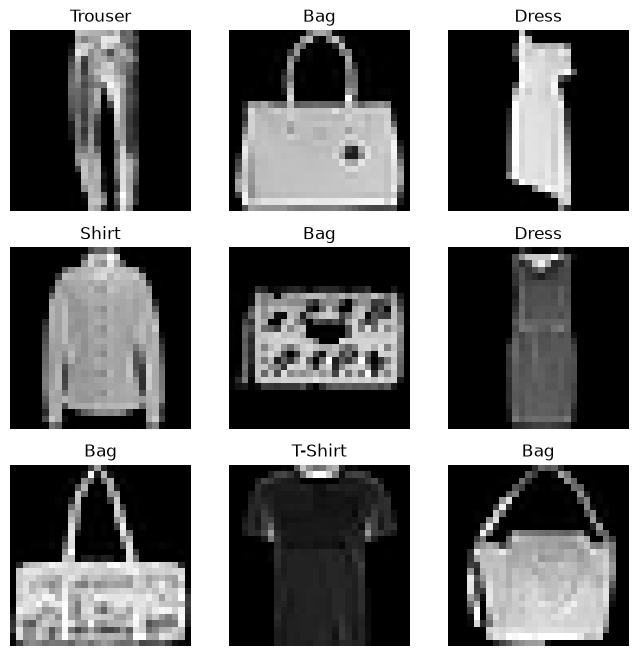

In [2]:
# Iterating and visualizing the dataset
labels_map = {
    0: "T-Shirt",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle Boot",
}
figure = plt.figure(figsize=(8,8))
cols, rows = 3, 3
for i in range(1, cols * rows + 1):
    sample_idx = torch.randint(len(training_data), size=(1,)).item()
    img, label = training_data[sample_idx]
    figure.add_subplot(rows, cols, i)
    plt.title(labels_map[label])
    plt.axis("off")
    plt.imshow(img.squeeze(), cmap="gray")
plt.show()

In [3]:
# Datasets retrieve features/labels one sample a time.
# Dataloader loads data in mini batches.
from torch.utils.data import DataLoader

train_dataloader = DataLoader(training_data, batch_size=64, shuffle=True)
test_dataloader = DataLoader(test_data, batch_size=64, shuffle=True)

Feature batch shape: torch.Size([64, 1, 28, 28])
Label batch shape: torch.Size([64])


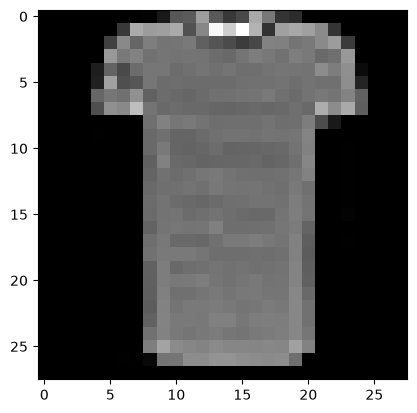

Label: 0


In [5]:
# Display img and label, interating via dataloader
train_features, train_labels = next(iter(train_dataloader))
print(f"Feature batch shape: {train_features.size()}")
print(f"Label batch shape: {train_labels.size()}")
img = train_features[0].squeeze()
label = train_labels[0]
plt.imshow(img, cmap="gray")
plt.show()
print(f"Label: {label}")

In [13]:
# Use transforms to make data suitable for training
# transform: modify the features
# target_transform: modify the labels
import torch.nn.functional as F

# v2.Compose: runs each transform in order, pass the result from each transform to next
# v2.ToImage: converts the PIL img torchvision.tv_tensors.Image, a specialized PyTorch tensor
#             size is [1, 28, 28], 1 channel, 28 pixel high, 28 wide.
#             Pixel values remain integers [0, 255].
# v2.ToDtype: converts integers to float32; for uint8 imgs, "scale=True" divides each pixel value by 255.
ds = datasets.FashionMNIST(
    root = "data",
    train = True,
    download = True,
    transform = v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)]),
    target_transform = v2.Lambda(
        lambda y: F.one_hot(torch.tensor(y), num_classes=10).float()
    ),
)
img, label = ds[0]
print(f"label: {label}")
print(f"img: {type(img)}, {img.shape}, {img.dtype}")
print(f"img pixel range: {img.min().item()} to {img.max().item()}")
print(img[0, 10:15, 17:24])

label: tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 1.])
img: <class 'torchvision.tv_tensors._image.Image'>, torch.Size([1, 28, 28]), torch.float32
img pixel range: 0.0 to 1.0
tensor([[0.7765, 0.7059, 0.8314, 0.8235, 0.8275, 0.8353, 0.8745],
        [0.7529, 0.6627, 0.8902, 0.8157, 0.8549, 0.8784, 0.8314],
        [0.7961, 0.7765, 0.8667, 0.8431, 0.8353, 0.8706, 0.8627],
        [0.9412, 0.9098, 0.8353, 0.8549, 0.8745, 0.9176, 0.8510],
        [0.8588, 0.8706, 0.8667, 0.8471, 0.8745, 0.8980, 0.8431]])
